# Experiment 7: IMDB Sentiment Analysis Model Comparison

## Lab Questions / Objectives

1. **Implement sentiment analysis using Logistic regression, LSTM, and Vanilla Transformer models and BERT pretrained model on IMDB Movie Reviews Dataset and perform comparative analysis among all the models.**
   * *Evaluation metrics:* F1-Score, Precision, Recall, and Confusion Matrix.
   * *Datasets:* IMDB Movie Reviews Dataset (Kaggle / Ankit152 GitHub repository).

Using device: cpu
Loading IMDB dataset from Hugging Face...

--- Training Model 1: Logistic Regression ---

--- Training Model 2: LSTM ---

--- Training Model 3: Vanilla Transformer ---

--- Training Model 4: Pretrained BERT ---


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



FINAL COMPARATIVE PERFORMANCE METRICS
Model                  | Precision  | Recall     | F1-Score  
------------------------------------------------------------
Logistic Regression    | 0.8378     | 0.7440     | 0.7881    
LSTM                   | 0.5214     | 0.7800     | 0.6250    
Vanilla Transformer    | 0.7572     | 0.5240     | 0.6194    
BERT                   | 0.8285     | 0.9080     | 0.8664    


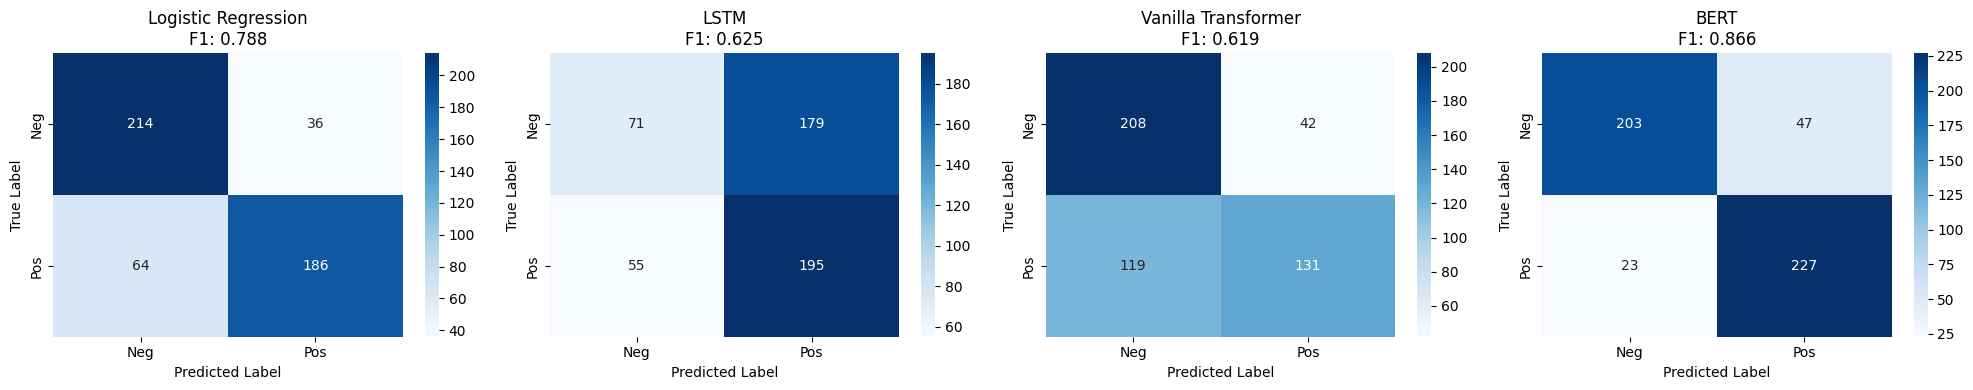

In [4]:
# ==============================================================================
# EXPERIMENT 7: IMDB Sentiment Analysis Model Comparison (Complete Code)
# ==============================================================================
# Ensure all dependencies are installed:
# !pip install -q transformers datasets scikit-learn torch matplotlib seaborn

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set random seed for reproducibility
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# 1. Load IMDB Dataset with Proper Namespace & Balanced Class Slicing
print("Loading IMDB dataset from Hugging Face...")
dataset = load_dataset("stanfordnlp/imdb")

raw_train_texts = dataset['train']['text']
raw_train_labels = dataset['train']['label']
raw_test_texts = dataset['test']['text']
raw_test_labels = dataset['test']['label']

# Extract balanced training samples (1000 negative, 1000 positive)
train_neg = [i for i, label in enumerate(raw_train_labels) if label == 0][:1000]
train_pos = [i for i, label in enumerate(raw_train_labels) if label == 1][:1000]
train_indices = train_neg + train_pos

train_texts = [raw_train_texts[i] for i in train_indices]
train_labels = [raw_train_labels[i] for i in train_indices]

# Extract balanced testing samples (250 negative, 250 positive)
test_neg = [i for i, label in enumerate(raw_test_labels) if label == 0][:250]
test_pos = [i for i, label in enumerate(raw_test_labels) if label == 1][:250]
test_indices = test_neg + test_pos

test_texts = [raw_test_texts[i] for i in test_indices]
test_labels = [raw_test_labels[i] for i in test_indices]

results = {}

# ------------------------------------------------------------------------------
# MODEL 1: Logistic Regression + TF-IDF
# ------------------------------------------------------------------------------
print("\n--- Training Model 1: Logistic Regression ---")
vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(train_texts)
X_test = vectorizer.transform(test_texts)

lr_model = LogisticRegression()
lr_model.fit(X_train, train_labels)
lr_preds = lr_model.predict(X_test)

p, r, f1, _ = precision_recall_fscore_support(test_labels, lr_preds, average='binary')
results['Logistic Regression'] = {
    'Precision': p, 'Recall': r, 'F1': f1,
    'cm': confusion_matrix(test_labels, lr_preds)
}

# ------------------------------------------------------------------------------
# MODEL 2: PyTorch LSTM Classifier
# ------------------------------------------------------------------------------
print("\n--- Training Model 2: LSTM ---")
tokenizer_base = lambda text: text.lower().replace('<br />', '').split()[:150]
vocab_lst = set(w for text in train_texts for w in tokenizer_base(text))
w2i = {w: i+2 for i, w in enumerate(vocab_lst)}
w2i['<pad>'] = 0
w2i['<unk>'] = 1

def encode(text):
    return [w2i.get(w, 1) for w in tokenizer_base(text)]

class TextDataset(Dataset):
    def __init__(self, texts, labels):
        self.data = [encode(t) for t in texts]
        self.labels = labels
    def __len__(self): return len(self.data)
    def __getitem__(self, idx): return torch.tensor(self.data[idx]), torch.tensor(self.labels[idx])

def collate_fn(batch):
    texts, labels = zip(*batch)
    max_len = max(len(t) for t in texts)
    padded = torch.zeros((len(texts), max_len), dtype=torch.long)
    for i, t in enumerate(texts):
        padded[i, :len(t)] = t
    return padded, torch.tensor(labels)

train_loader = DataLoader(TextDataset(train_texts, train_labels), batch_size=32, shuffle=True, collate_fn=collate_fn)
test_loader = DataLoader(TextDataset(test_texts, test_labels), batch_size=32, shuffle=False, collate_fn=collate_fn)

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, 2)
    def forward(self, x):
        _, (h, _) = self.lstm(self.embed(x))
        return self.fc(h[-1])

lstm = LSTMClassifier(len(w2i)+2).to(device)
opt = torch.optim.Adam(lstm.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

for epoch in range(3):
    lstm.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        opt.zero_grad()
        loss = criterion(lstm(x), y)
        loss.backward()
        opt.step()

lstm.eval()
lstm_preds = []
with torch.no_grad():
    for x, y in test_loader:
        lstm_preds.extend(torch.argmax(lstm(x.to(device)), dim=1).cpu().numpy())

p, r, f1, _ = precision_recall_fscore_support(test_labels, lstm_preds, average='binary')
results['LSTM'] = {
    'Precision': p, 'Recall': r, 'F1': f1,
    'cm': confusion_matrix(test_labels, lstm_preds)
}

# ------------------------------------------------------------------------------
# MODEL 3: Vanilla Transformer Encoder
# ------------------------------------------------------------------------------
print("\n--- Training Model 3: Vanilla Transformer ---")
class VanillaTransformerClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, num_heads=4, hidden_dim=64):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        encoder_layer = nn.TransformerEncoderLayer(d_model=embed_dim, nhead=num_heads, dim_feedforward=hidden_dim, batch_first=True)
        self.transformer = nn.TransformerEncoder(encoder_layer, num_layers=1)
        self.fc = nn.Linear(embed_dim, 2)
    def forward(self, x):
        x = self.embed(x)
        x = self.transformer(x)
        x = x.mean(dim=1)  # Mean pooling over sequence length
        return self.fc(x)

trans_model = VanillaTransformerClassifier(len(w2i)+2).to(device)
t_opt = torch.optim.Adam(trans_model.parameters(), lr=0.001)

trans_model.train()
for epoch in range(3):
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        t_opt.zero_grad()
        loss = criterion(trans_model(x), y)
        loss.backward()
        t_opt.step()

trans_model.eval()
trans_preds = []
with torch.no_grad():
    for x, y in test_loader:
        trans_preds.extend(torch.argmax(trans_model(x.to(device)), dim=1).cpu().numpy())

p, r, f1, _ = precision_recall_fscore_support(test_labels, trans_preds, average='binary')
results['Vanilla Transformer'] = {
    'Precision': p, 'Recall': r, 'F1': f1,
    'cm': confusion_matrix(test_labels, trans_preds)
}

# ------------------------------------------------------------------------------
# MODEL 4: Pretrained BERT Model (`bert-base-uncased`)
# ------------------------------------------------------------------------------
print("\n--- Training Model 4: Pretrained BERT ---")
bert_tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')
bert_model = AutoModelForSequenceClassification.from_pretrained('bert-base-uncased', num_labels=2).to(device)

class BertDataset(Dataset):
    def __init__(self, texts, labels):
        self.encodings = bert_tokenizer(texts, truncation=True, padding=True, max_length=128, return_tensors="pt")
        self.labels = torch.tensor(labels)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['labels'] = self.labels[idx]
        return item

b_train_loader = DataLoader(BertDataset(train_texts, train_labels), batch_size=16, shuffle=True)
b_test_loader = DataLoader(BertDataset(test_texts, test_labels), batch_size=16, shuffle=False)
b_optimizer = AdamW(bert_model.parameters(), lr=2e-5)

bert_model.train()
for batch in b_train_loader:
    b_optimizer.zero_grad()
    outputs = bert_model(batch['input_ids'].to(device), attention_mask=batch['attention_mask'].to(device), labels=batch['labels'].to(device))
    outputs.loss.backward()
    b_optimizer.step()

bert_model.eval()
bert_preds = []
with torch.no_grad():
    for batch in b_test_loader:
        outputs = bert_model(batch['input_ids'].to(device), attention_mask=batch['attention_mask'].to(device))
        bert_preds.extend(torch.argmax(outputs.logits, dim=1).cpu().numpy())

p, r, f1, _ = precision_recall_fscore_support(test_labels, bert_preds, average='binary')
results['BERT'] = {
    'Precision': p, 'Recall': r, 'F1': f1,
    'cm': confusion_matrix(test_labels, bert_preds)
}

# ------------------------------------------------------------------------------
# FINAL COMPARATIVE ANALYSIS & CONFUSION MATRIX PLOTS
# ------------------------------------------------------------------------------
print("\n" + "="*65)
print("FINAL COMPARATIVE PERFORMANCE METRICS")
print("="*65)
print(f"{'Model':<22} | {'Precision':<10} | {'Recall':<10} | {'F1-Score':<10}")
print("-" * 60)
for m_name, metrics in results.items():
    print(f"{m_name:<22} | {metrics['Precision']:<10.4f} | {metrics['Recall']:<10.4f} | {metrics['F1']:<10.4f}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for idx, (m_name, metrics) in enumerate(results.items()):
    sns.heatmap(metrics['cm'], annot=True, fmt='d', ax=axes[idx], cmap='Blues',
                xticklabels=['Neg', 'Pos'], yticklabels=['Neg', 'Pos'])
    axes[idx].set_title(f"{m_name}\nF1: {metrics['F1']:.3f}")
    axes[idx].set_ylabel('True Label')
    axes[idx].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()